# Segmentación de naranjas con YOLO26n-seg

Notebook para probar **YOLO26n-seg** (preentrenado en COCO) en la segmentación de naranjas,
medir qué tan bien anda con el dataset *Orange occlusion* de Roboflow y exportarlo a **ONNX**
para usarlo en la web de ThreeDetection.

**Flujo:** GPU → entorno → dataset → prueba visual → mAP → ONNX para la web → *(opcional)* transfer learning y fine-tuning.

## 0. Antes de empezar

1. **GPU:** menú *Entorno de ejecución → Cambiar tipo de entorno de ejecución → T4 GPU*.
2. **API key de Roboflow:** en la barra izquierda, ícono de la llave (🔑 *Secrets*), agregar
   `ROBOFLOW_API_KEY` con tu clave y activar *Acceso del notebook*.
3. *Entorno de ejecución → Ejecutar todas*.

Los resultados (métricas, gráficos, modelos y el ONNX para la web) quedan en
**Google Drive**, en `MyDrive/naranjas/`. El dataset se descarga en `/content` porque ahí se lee más rápido.

## 1. GPU

In [ ]:
!nvidia-smi

import torch

if not torch.cuda.is_available():
    raise RuntimeError(
        'No hay GPU. Andá a "Entorno de ejecución > Cambiar tipo de entorno de ejecución", '
        'elegí "T4 GPU" y volvé a ejecutar el notebook.'
    )
print('GPU:', torch.cuda.get_device_name(0))

Wed Oct 28 00:33:00 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   34C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## 2. Entorno

Se monta Drive, se instalan las librerías y se definen las rutas y parámetros generales.

In [ ]:
!pip install -q ultralytics roboflow onnx onnxruntime onnxslim

In [ ]:
from pathlib import Path

from google.colab import drive

drive.mount('/content/drive')

DRIVE_DIR = Path('/content/drive/MyDrive/naranjas')   # resultados que se conservan
WORK_DIR = Path('/content')                            # dataset y archivos temporales

Mounted at /content/drive


In [ ]:
import json
import shutil

import cv2
import matplotlib.pyplot as plt
import numpy as np
import onnxruntime as ort
import pandas as pd
import ultralytics
import yaml
from IPython.display import display
from ultralytics import YOLO

ultralytics.checks()

DRIVE_DIR.mkdir(parents=True, exist_ok=True)
RUNS_DIR = DRIVE_DIR / 'runs'      # gráficos de validación y entrenamientos

IMGSZ = 640          # tamaño de entrada del modelo (también el de la web)
CONF = 0.25          # confianza mínima para contar una naranja
COCO_ORANGE = 49     # índice de la clase "orange" en COCO
IMG_EXT = {'.jpg', '.jpeg', '.png', '.bmp', '.webp'}

Ultralytics 8.4.191 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Setup complete ✅ (2 CPUs, 12.7 GB RAM, 42.7/112.6 GB disk)


## 3. Dataset

Se descarga *Orange occlusion dataset* (versión 5) en formato YOLO. Roboflow arma un `data.yaml`
con rutas relativas que a veces fallan, así que se reescribe con rutas absolutas.

El dataset etiqueta dos clases: **hojas** (`leaf`) y **naranjas** (`orange`). Como solo interesan las
naranjas, se arma una copia en `/content/orange-solo` que conserva únicamente sus etiquetas, renumeradas
como clase 0. Todo el notebook (conteos, mAP y entrenamiento) usa esa copia.

In [ ]:
from google.colab import userdata
from roboflow import Roboflow

rf = Roboflow(api_key=userdata.get('ROBOFLOW_API_KEY'))
dataset = (
    rf.workspace('canerbeldek')
    .project('orange-occlusion-dataset')
    .version(5)
    .download('yolov8', location=str(WORK_DIR / 'orange-occlusion'))
)
ORIGEN_DIR = Path(dataset.location)   # dataset tal como viene de Roboflow (hojas y naranjas)

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to /content/orange-occlusion in yolov8:: 100%|██████████| 2005/2005 [00:00<00:00, 2469.09it/s]


In [ ]:
original = yaml.safe_load((ORIGEN_DIR / 'data.yaml').read_text())
nombres = original['names']
CLASES_ORIGEN = dict(enumerate(nombres)) if isinstance(nombres, list) else {int(k): v for k, v in nombres.items()}
print('Clases del dataset original:', CLASES_ORIGEN)
ID_NARANJA = next(k for k, v in CLASES_ORIGEN.items() if v.lower() == 'orange')

# Roboflow llama "valid" a la carpeta de validación.
SPLITS = {
    split: carpeta
    for split, carpeta in [('train', 'train'), ('val', 'valid'), ('test', 'test')]
    if (ORIGEN_DIR / carpeta / 'images').is_dir()
}
if 'test' not in SPLITS:
    print('⚠️ El dataset no trae split de test: se evalúa sobre validación.')
    SPLITS['test'] = SPLITS['val']

# Copia con solo las naranjas, como clase 0. Las demás etiquetas (hojas) se descartan.
DATASET_DIR = WORK_DIR / 'orange-solo'
shutil.rmtree(DATASET_DIR, ignore_errors=True)   # borra también los labels.cache viejos
descartadas = {}
for carpeta in sorted(set(SPLITS.values())):
    shutil.copytree(ORIGEN_DIR / carpeta / 'images', DATASET_DIR / carpeta / 'images')
    (DATASET_DIR / carpeta / 'labels').mkdir(parents=True)
    descartadas[carpeta] = 0
    for txt in (ORIGEN_DIR / carpeta / 'labels').glob('*.txt'):
        naranjas = []
        for linea in txt.read_text().splitlines():
            valores = linea.split()
            if not valores:
                continue
            if int(valores[0]) == ID_NARANJA:
                naranjas.append(' '.join(['0', *valores[1:]]))
            else:
                descartadas[carpeta] += 1
        (DATASET_DIR / carpeta / 'labels' / txt.name).write_text('\n'.join(naranjas))
print('Etiquetas descartadas (no son naranja):', descartadas)

DATA_YAML = DATASET_DIR / 'data_local.yaml'
DATA_YAML.write_text(yaml.safe_dump({
    'path': str(DATASET_DIR),
    'train': f"{SPLITS['train']}/images",
    'val': f"{SPLITS['val']}/images",
    'test': f"{SPLITS['test']}/images",
    'names': {0: 'orange'},
}, allow_unicode=True))

TEST_IMAGES = DATASET_DIR / SPLITS['test'] / 'images'
TEST_LABELS = DATASET_DIR / SPLITS['test'] / 'labels'
print(DATA_YAML.read_text())

Clases del dataset original: {0: 'leaf', 1: 'orange'}
Etiquetas descartadas (no son naranja): {'test': 1019, 'train': 6748, 'valid': 1903}
names:
  0: orange
path: /content/orange-solo
test: test/images
train: train/images
val: valid/images



### Conteo por split y tipo de etiqueta

Cada línea de una etiqueta YOLO es un objeto. Si tiene 5 valores es una **caja**
(`clase x y ancho alto`); si tiene más, es un **polígono** (`clase x1 y1 x2 y2 ...`).
Para medir el mAP de máscara y para entrenar segmentación hacen falta polígonos.

In [ ]:
def imagenes(carpeta):
    return sorted(p for p in Path(carpeta).iterdir() if p.suffix.lower() in IMG_EXT)


def leer_etiquetas(ruta_txt):
    """Devuelve una lista de (clase, coordenadas normalizadas) por objeto."""
    if not ruta_txt.exists():
        return []
    objetos = []
    for linea in ruta_txt.read_text().splitlines():
        valores = linea.split()
        if len(valores) >= 5:
            objetos.append((int(valores[0]), np.array(valores[1:], dtype=float)))
    return objetos


def etiqueta_de(imagen):
    return imagen.parent.parent / 'labels' / f'{imagen.stem}.txt'


filas = []
tipos = {'cajas': 0, 'poligonos': 0}
for split, carpeta in SPLITS.items():
    imgs = imagenes(DATASET_DIR / carpeta / 'images')
    objetos = [obj for img in imgs for obj in leer_etiquetas(etiqueta_de(img))]
    for _, coords in objetos:
        tipos['cajas' if len(coords) == 4 else 'poligonos'] += 1
    filas.append({'split': split, 'carpeta': carpeta, 'imagenes': len(imgs), 'naranjas': len(objetos),
                  'naranjas por imagen': round(len(objetos) / max(len(imgs), 1), 1)})

display(pd.DataFrame(filas))
print('Tipos de etiqueta:', tipos)

HAY_POLIGONOS = tipos['poligonos'] > 0
if not HAY_POLIGONOS:
    print('⚠️ El dataset solo tiene cajas: se evalúan cajas y el mAP de máscara queda vacío.')
elif tipos['cajas']:
    print('⚠️ El dataset mezcla cajas y polígonos: Ultralytics va a descartar los polígonos.')

,split,carpeta,imagenes,naranjas,naranjas por imagen
0,train,train,700,2574,3.7
1,val,valid,200,785,3.9
2,test,test,100,390,3.9


Tipos de etiqueta: {'cajas': 0, 'poligonos': 3749}


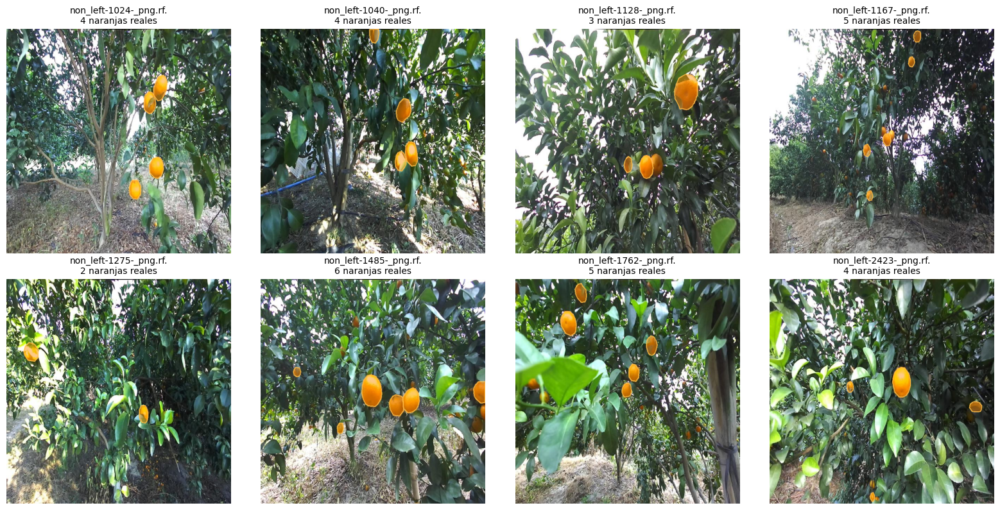

In [ ]:
def dibujar_reales(imagen):
    """Imagen RGB con las naranjas etiquetadas pintadas encima."""
    img = cv2.cvtColor(cv2.imread(str(imagen)), cv2.COLOR_BGR2RGB)
    h, w = img.shape[:2]
    capa = img.copy()
    for _, coords in leer_etiquetas(etiqueta_de(imagen)):
        if len(coords) == 4:
            cx, cy, bw, bh = coords * [w, h, w, h]
            p1 = (int(cx - bw / 2), int(cy - bh / 2))
            p2 = (int(cx + bw / 2), int(cy + bh / 2))
            cv2.rectangle(capa, p1, p2, (255, 140, 0), -1)
            cv2.rectangle(img, p1, p2, (255, 220, 120), 2)
        else:
            puntos = (coords.reshape(-1, 2) * [w, h]).astype(np.int32)
            cv2.fillPoly(capa, [puntos], (255, 140, 0))
            cv2.polylines(img, [puntos], True, (255, 220, 120), 2)
    return cv2.addWeighted(capa, 0.45, img, 0.55, 0)


def grilla(imagenes_rgb, titulos, columnas=4):
    filas_g = (len(imagenes_rgb) + columnas - 1) // columnas
    fig, ejes = plt.subplots(filas_g, columnas, figsize=(4 * columnas, 4 * filas_g), squeeze=False)
    for eje in ejes.flat:
        eje.axis('off')
    for eje, img, titulo in zip(ejes.flat, imagenes_rgb, titulos):
        eje.imshow(img)
        eje.set_title(titulo, fontsize=10)
    plt.tight_layout()
    plt.show()


imagenes_test = imagenes(TEST_IMAGES)
muestra = imagenes_test[:8]
grilla([dibujar_reales(p) for p in muestra],
       [f'{p.name[:22]}\n{len(leer_etiquetas(etiqueta_de(p)))} naranjas reales' for p in muestra])

## 4. Modelo base: prueba visual

YOLO26n-seg preentrenado en COCO ya conoce la clase **orange** (índice 49). Sin entrenar nada,
se le pide que segmente solo esa clase y se compara cuántas naranjas encuentra contra las etiquetadas.

Clase 49 = orange


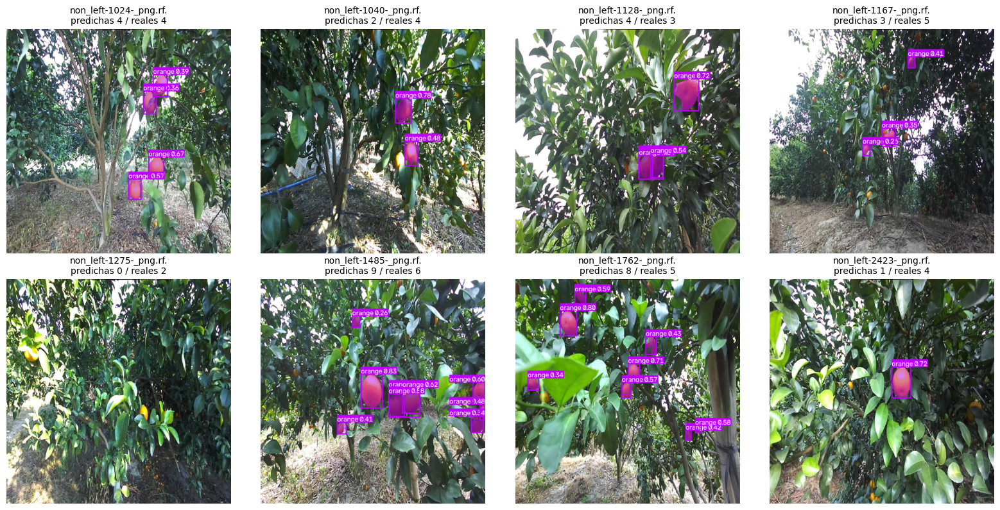

Error absoluto medio del conteo: 1.65 naranjas por imagen
Predichas en total: 303 | reales: 390


,imagen,reales,predichas,error
0,non_left-1024-_png.rf.df72efcec2074f1b82b17d74...,4,4,0
1,non_left-1040-_png.rf.f5bdd7bb8395ab0fef7da608...,4,2,-2
2,non_left-1128-_png.rf.5f28eed6324fd15dc722f975...,3,4,1
3,non_left-1167-_png.rf.0b4e0ba4e71155042d25bd4e...,5,3,-2
4,non_left-1275-_png.rf.e7abf278a8e1de797ea5b2e4...,2,0,-2
5,non_left-1485-_png.rf.353bc24da8077705023b57e3...,6,9,3
6,non_left-1762-_png.rf.4f4381f0c14906583d4b4d46...,5,8,3
7,non_left-2423-_png.rf.d3e55a17a558d269074b82f9...,4,1,-3
8,non_left-255-_png.rf.3ca1ab1702536969313ac8b4e...,4,2,-2
9,non_left-2633-_png.rf.1c549f86b916add9c44b0829...,5,5,0


In [ ]:
modelo_base = YOLO('yolo26n-seg.pt')
print('Clase', COCO_ORANGE, '=', modelo_base.names[COCO_ORANGE])


def conteo_por_imagen(modelo, clases=None, imgsz=IMGSZ, ejemplos=0):
    """Naranjas predichas vs. reales en cada imagen de test, y algunas imágenes dibujadas."""
    filas_c, dibujos = [], []
    for r in modelo.predict(imagenes_test, classes=clases, conf=CONF, imgsz=imgsz, stream=True, verbose=False):
        ruta = Path(r.path)
        filas_c.append({'imagen': ruta.name,
                        'reales': len(leer_etiquetas(etiqueta_de(ruta))),
                        'predichas': len(r.boxes)})
        if len(dibujos) < ejemplos:
            dibujos.append((r.plot()[..., ::-1], filas_c[-1]))
    tabla = pd.DataFrame(filas_c)
    tabla['error'] = tabla['predichas'] - tabla['reales']
    return tabla, dibujos


conteo_base, dibujos = conteo_por_imagen(modelo_base, clases=[COCO_ORANGE], ejemplos=8)
grilla([img for img, _ in dibujos],
       [f"{f['imagen'][:22]}\npredichas {f['predichas']} / reales {f['reales']}" for _, f in dibujos])

MAE_BASE = conteo_base['error'].abs().mean()
print(f'Error absoluto medio del conteo: {MAE_BASE:.2f} naranjas por imagen')
print(f"Predichas en total: {conteo_base['predichas'].sum()} | reales: {conteo_base['reales'].sum()}")
conteo_base.to_csv(DRIVE_DIR / 'conteo_base.csv', index=False)
display(conteo_base.head(15))

## 5. Modelo base: mAP

El modelo predice con los índices de COCO (naranja = 49) y el dataset etiqueta las naranjas como 0.
Para que Ultralytics compare naranja con naranja se copian las imágenes y etiquetas de test
**cambiando la clase a 49**, con un `data_coco.yaml` que tiene los 80 nombres de COCO.

> `val()` no filtra por `classes` (ese argumento es de `predict()`), pero no hace falta:
> el mAP se promedia solo sobre las clases que aparecen en las etiquetas reales, es decir, solo
> la 49. Si el modelo confunde una naranja con otra clase (por ejemplo `apple`), cuenta como
> naranja no encontrada.

In [ ]:
COCO_DIR = WORK_DIR / 'coco_eval'
shutil.rmtree(COCO_DIR, ignore_errors=True)   # borra también el labels.cache viejo
shutil.copytree(TEST_IMAGES, COCO_DIR / 'images')
(COCO_DIR / 'labels').mkdir(parents=True)

for imagen in imagenes(COCO_DIR / 'images'):
    lineas = [f"{COCO_ORANGE} {' '.join(f'{v:.6g}' for v in coords)}"
              for _, coords in leer_etiquetas(TEST_LABELS / f'{imagen.stem}.txt')]
    (COCO_DIR / 'labels' / f'{imagen.stem}.txt').write_text('\n'.join(lineas))

COCO_YAML = COCO_DIR / 'data_coco.yaml'
COCO_YAML.write_text(yaml.safe_dump({
    'path': str(COCO_DIR), 'train': 'images', 'val': 'images', 'test': 'images',
    'names': modelo_base.names,
}, allow_unicode=True))
print(f'{len(imagenes(COCO_DIR / "images"))} imágenes de test remapeadas a la clase {COCO_ORANGE}.')

100 imágenes de test remapeadas a la clase 49.


In [ ]:
def resumen(nombre, metricas, mae=np.nan):
    """Métricas principales de una corrida de val() en una fila."""
    fila = {
        'modelo': nombre,
        'caja mAP50': metricas.box.map50,
        'caja mAP50-95': metricas.box.map,
        'máscara mAP50': metricas.seg.map50 if HAY_POLIGONOS else np.nan,
        'máscara mAP50-95': metricas.seg.map if HAY_POLIGONOS else np.nan,
        'precisión': metricas.box.mp,
        'recall': metricas.box.mr,
        'MAE conteo': mae,
        'inferencia (ms/img)': metricas.speed['inference'],
    }
    return {k: round(float(v), 4) if isinstance(v, (float, np.floating)) else v for k, v in fila.items()}


metricas_base = modelo_base.val(data=str(COCO_YAML), split='test', imgsz=IMGSZ, batch=16,
                                project=str(RUNS_DIR), name='val_base', exist_ok=True)

tabla_base = pd.DataFrame([resumen('Base (COCO, clase 49)', metricas_base, MAE_BASE)])
tabla_base.to_csv(DRIVE_DIR / 'metricas_base.csv', index=False)
display(tabla_base)

Ultralytics 8.4.191 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n-seg summary (fused): 136 layers, 2,722,980 parameters, 0 gradients, 9.3 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1174.4±712.3 MB/s, size: 96.0 KB)
val: Scanning /content/coco_eval/labels... 100 images, 2 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 100/100 1.8Kit/s 0.1s
val: New cache created: /content/coco_eval/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 7/7 1.4it/s 5.0s
                   all        100        390       0.66      0.685      0.717      0.495      0.649      0.667      0.685      0.424
                orange         98        390       0.66      0.685      0.717      0.495      0.649      0.667      0.685      0.424
Speed: 6.1ms preprocess, 9.7ms inference, 0.0ms loss, 7.8ms postprocess per image
Results saved to /content/drive/MyDrive/naranjas/ru

,modelo,caja mAP50,caja mAP50-95,máscara mAP50,máscara mAP50-95,precisión,recall,MAE conteo,inferencia (ms/img)
0,"Base (COCO, clase 49)",0.7175,0.4953,0.6847,0.4235,0.6595,0.6854,1.65,9.6918


**Cómo leerlo:** *mAP50* mide si encuentra las naranjas con una superposición de al menos 50 %;
*mAP50-95* exige además bordes precisos. *Precisión* = de lo que marcó, cuánto era naranja;
*recall* = de las naranjas reales, cuántas encontró. Si el recall es bajo (típico con naranjas
chicas o tapadas por hojas), conviene pasar a la sección 7.

## 6. Exportar a ONNX para la web

Se exporta con `nms=True`: el ONNX trae el NMS adentro y devuelve hasta 300 detecciones ya filtradas,
así la web no tiene que hacer NMS en JavaScript.

> **¿Por qué no `nms=False`?** YOLO26 tiene dos cabezas: una *uno-a-muchos* que necesita NMS y otra
> *uno-a-uno* que no lo necesita. `predict()` y `val()` del `.pt` usan la primera, y `nms=False` exporta
> la segunda, que da otras confianzas. Con `nms=True` el ONNX usa la misma cabeza que se midió en la
> sección 5, así que el mAP de arriba es el del modelo que corre en la web. Las dos salidas tienen el
> mismo formato y la web acepta cualquiera de los dos.

In [ ]:
onnx_base = Path(modelo_base.export(format='onnx', imgsz=IMGSZ, nms=True, conf=CONF, device='cpu'))

sesion = ort.InferenceSession(str(onnx_base), providers=['CPUExecutionProvider'])
for e in sesion.get_inputs():
    print('Entrada:', e.name, e.shape)
for s in sesion.get_outputs():
    print('Salida: ', s.name, s.shape)
print('\n[1, 300, 38] = 300 detecciones x (x1, y1, x2, y2, confianza, clase, 32 coeficientes de máscara)')
print('[1, 32, 160, 160] = 32 prototipos de máscara; cada máscara es sigmoide(coeficientes · prototipos)')

Ultralytics 8.4.191 🚀 Python-3.13.16 torch-2.11.0+cu130 CPU (Intel Xeon CPU @ 2.00GHz)
💡 ProTip: Export to OpenVINO format for best performance on Intel hardware. Learn more at https://docs.ultralytics.com/integrations/openvino
YOLO26n-seg summary (fused): 136 layers, 2,722,980 parameters, 0 gradients, 9.3 GFLOPs

PyTorch: starting from 'yolo26n-seg.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) ((1, 300, 38), (1, 32, 160, 160)) (6.4 MB)

ONNX: starting export with onnx 1.23.2 opset 18...
ONNX: slimming with onnxslim 0.1.98...
ONNX: export success ✅ 2.9s, saved as 'yolo26n-seg.onnx' (10.8 MB)

Export complete (3.3s)
Results saved to /content/yolo26n-seg.onnx
Predict:         yolo predict task=segment model=yolo26n-seg.onnx imgsz=640 
Validate:        yolo val task=segment model=yolo26n-seg.onnx imgsz=640  
Visualize:       https://netron.app
Entrada: images [1, 3, 640, 640]
Salida:  output0 [1, 300, 38]
Salida:  output1 [1, 32, 160, 160]

[1, 300, 38] = 300 detecciones 

In [ ]:
# Predicción de control: el .onnx tiene que contar lo mismo que el .pt.
# rect=False hace que el .pt también rellene la imagen hasta 640x640, como el ONNX y la web.
modelo_onnx = YOLO(str(onnx_base), task='segment')
for imagen in imagenes_test[:3]:
    n_pt = len(modelo_base.predict(imagen, classes=[COCO_ORANGE], conf=CONF, imgsz=IMGSZ, rect=False,
                                   verbose=False)[0].boxes)
    n_onnx = len(modelo_onnx.predict(imagen, classes=[COCO_ORANGE], conf=CONF, imgsz=IMGSZ, verbose=False)[0].boxes)
    print(f"{imagen.name[:30]:30}  .pt: {n_pt:3}  .onnx: {n_onnx:3}  {'✅' if n_pt == n_onnx else '⚠️'}")

Loading yolo26n-seg.onnx for ONNX Runtime inference...
requirements: Ultralytics requirement ['onnxruntime-gpu'] not found, attempting AutoUpdate...
Using Python 3.13.16 environment at: /usr
Resolved 5 packages in 260ms
Prepared 1 package in 3.80s
Installed 1 package in 44ms
 + onnxruntime-gpu==1.31.1

requirements: AutoUpdate success ✅ 4.4s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect

Using ONNX Runtime 1.31.1 with CPUExecutionProvider
WARNING ⚠️ CUDA requested but CUDAExecutionProvider not available. Using CPU...
non_left-1024-_png.rf.df72efce  .pt:   4  .onnx:   4  ✅
non_left-1040-_png.rf.f5bdd7bb  .pt:   2  .onnx:   2  ✅
non_left-1128-_png.rf.5f28eed6  .pt:   4  .onnx:   4  ✅


In [ ]:
def guardar_para_web(ruta_onnx, carpeta, nombre, class_id, imgsz, names):
    """Copia el ONNX y escribe el model.json que lee la web (js/demo/segmenter.js)."""
    carpeta.mkdir(parents=True, exist_ok=True)
    shutil.copy(ruta_onnx, carpeta / 'orange-seg.onnx')
    s = ort.InferenceSession(str(ruta_onnx), providers=['CPUExecutionProvider'])
    info = {
        'name': nombre,
        'file': 'orange-seg.onnx',
        'imgsz': imgsz,
        'classId': class_id,
        'conf': CONF,
        'input': s.get_inputs()[0].name,
        'outputs': [{'name': o.name, 'shape': o.shape} for o in s.get_outputs()],
        'names': {str(k): v for k, v in names.items()},
    }
    (carpeta / 'model.json').write_text(json.dumps(info, indent=2, ensure_ascii=False))
    tamano = (carpeta / 'orange-seg.onnx').stat().st_size / 1e6
    print(f'Guardado en {carpeta}: orange-seg.onnx ({tamano:.1f} MB) y model.json')


guardar_para_web(onnx_base, DRIVE_DIR / 'web', 'YOLO26n-seg (COCO, clase orange)',
                 COCO_ORANGE, IMGSZ, modelo_base.names)

Guardado en /content/drive/MyDrive/naranjas/web: orange-seg.onnx (11.3 MB) y model.json


Para usarlo en la web, copiá `MyDrive/naranjas/web/orange-seg.onnx` y `model.json` a
`ThreeDetection/model/` (ver el README del repo).

## 7. Transfer learning y fine-tuning

Esta sección solo se ejecuta con `ENTRENAR = True`. Sirve si el modelo base no alcanza.
Se entrena sobre el dataset filtrado de la sección 3, donde la naranja es la **clase 0** y no hay hojas:

1. **Transfer learning:** se congelan las primeras 10 capas (el *backbone*) y solo se entrena la cabeza.
2. **Fine-tuning:** se parte del mejor modelo de transfer, se descongela todo y se reentrena con
   `AdamW`, `lr0=1e-4` e imágenes de 1024 px (las naranjas chicas o tapadas se ven mejor), con
   augmentations de color y brillo para tolerar distintas luces.

Los entrenamientos se guardan en Drive: si Colab se desconecta, el último checkpoint queda en
`runs/<nombre>/weights/last.pt` y se puede retomar con `YOLO(ruta).train(resume=True)`.

In [ ]:
ENTRENAR = True

EPOCAS_TRANSFER = 30
EPOCAS_FT = 30
IMGSZ_FT = 1024      # el ONNX del fine-tuning se exporta con este tamaño (la web lo lee de model.json)
BATCH = 16
BATCH_FT = 8         # a 1024 px entra menos en la memoria de la T4
PACIENCIA = 10       # épocas sin mejora antes de cortar

In [ ]:
if ENTRENAR:
    modelo_transfer = YOLO('yolo26n-seg.pt')
    modelo_transfer.train(
        data=str(DATA_YAML), epochs=EPOCAS_TRANSFER, imgsz=IMGSZ, batch=BATCH,
        freeze=10, patience=PACIENCIA,
        project=str(RUNS_DIR), name='transfer', exist_ok=True,
    )
    MEJOR_TRANSFER = Path(modelo_transfer.trainer.best)
    print('Mejor modelo de transfer:', MEJOR_TRANSFER)
else:
    print('ENTRENAR = False: se saltea el transfer learning.')

Ultralytics 8.4.191 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/orange-solo/data_local.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=10, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n-seg.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=transfer, nbs=64, nms=None, opset=None, optimize=Fal

In [ ]:
if ENTRENAR:
    modelo_ft = YOLO(MEJOR_TRANSFER)
    modelo_ft.train(
        data=str(DATA_YAML), epochs=EPOCAS_FT, imgsz=IMGSZ_FT, batch=BATCH_FT,
        optimizer='AdamW', lr0=1e-4, warmup_epochs=0, patience=PACIENCIA,
        hsv_h=0.01,   # tono: poco, para que una naranja no pase a parecer un limón
        hsv_s=0.7,    # saturación
        hsv_v=0.5,    # brillo: sol directo, sombra, nublado
        project=str(RUNS_DIR), name='finetune', exist_ok=True,
    )
    MEJOR_FT = Path(modelo_ft.trainer.best)
    print('Mejor modelo de fine-tuning:', MEJOR_FT)
else:
    print('ENTRENAR = False: se saltea el fine-tuning.')

Ultralytics 8.4.191 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/orange-solo/data_local.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.01, hsv_s=0.7, hsv_v=0.5, imgsz=1024, iou=0.7, kobj=1.0, line_width=None, lr0=0.0001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/content/drive/MyDrive/naranjas/runs/transfer/weights/best.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=fi

### Comparación contra el modelo base

Los tres modelos se evalúan sobre el mismo split de test y solo contra las naranjas: el base con la copia
remapeada a la clase 49 y los entrenados con el dataset filtrado (clase 0).

Cada modelo se mide a **640 y a 1024 px**, para separar lo que aporta el entrenamiento de lo que aporta
la resolución. Las filas con el mismo tamaño muestran el efecto del modelo; el mismo modelo en los dos
tamaños muestra el efecto de la resolución y cuánto más lento se vuelve.

In [ ]:
if ENTRENAR:
    # nombre: (modelo, data.yaml, clases a predecir)
    modelos = {
        'Base': (modelo_base, COCO_YAML, [COCO_ORANGE]),
        'Transfer learning': (YOLO(MEJOR_TRANSFER), DATA_YAML, None),
        'Fine-tuning': (YOLO(MEJOR_FT), DATA_YAML, None),
    }
    filas_comp = []
    for imgsz in (IMGSZ, IMGSZ_FT):
        for nombre, (modelo, data, clases) in modelos.items():
            metricas = modelo.val(data=str(data), split='test', imgsz=imgsz,
                                  batch=BATCH if imgsz == IMGSZ else BATCH_FT, project=str(RUNS_DIR),
                                  name=f"val_{nombre.split()[0].lower()}_{imgsz}", exist_ok=True)
            conteo, _ = conteo_por_imagen(modelo, clases=clases, imgsz=imgsz)
            filas_comp.append(resumen(f'{nombre} ({imgsz} px)', metricas, conteo['error'].abs().mean()))

    comparacion = pd.DataFrame(filas_comp)
    comparacion.to_csv(DRIVE_DIR / 'metricas_comparacion.csv', index=False)
    display(comparacion)
else:
    print('ENTRENAR = False: no hay modelos entrenados para comparar.')

Ultralytics 8.4.191 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n-seg summary (fused): 136 layers, 2,722,980 parameters, 0 gradients, 9.3 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1337.6±1363.5 MB/s, size: 109.8 KB)
val: Scanning /content/coco_eval/labels.cache... 100 images, 2 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 100/100 30.0Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 7/7 1.3it/s 5.5s
                   all        100        390       0.66      0.685      0.717      0.495      0.649      0.667      0.685      0.424
                orange         98        390       0.66      0.685      0.717      0.495      0.649      0.667      0.685      0.424
Speed: 5.6ms preprocess, 7.5ms inference, 0.0ms loss, 9.1ms postprocess per image
Results saved to /content/drive/MyDrive/naranjas/runs/val_base_640
Ultralytics 8.4.191 🚀 Python-3.

,modelo,caja mAP50,caja mAP50-95,máscara mAP50,máscara mAP50-95,precisión,recall,MAE conteo,inferencia (ms/img)
0,Base (640 px),0.7175,0.4953,0.6847,0.4235,0.6595,0.6854,1.65,7.5078
1,Transfer learning (640 px),0.9105,0.7277,0.9123,0.6559,0.8788,0.8128,1.28,8.8079
2,Fine-tuning (640 px),0.9214,0.7276,0.9168,0.6492,0.8508,0.8770,1.08,8.4051
3,Base (1024 px),0.7087,0.4916,0.6795,0.4381,0.6388,0.6769,1.87,19.6629
4,Transfer learning (1024 px),0.9244,0.7460,0.9252,0.7013,0.8588,0.8615,1.37,18.8213
5,Fine-tuning (1024 px),0.9243,0.7592,0.9258,0.7131,0.8375,0.8615,1.20,18.8015


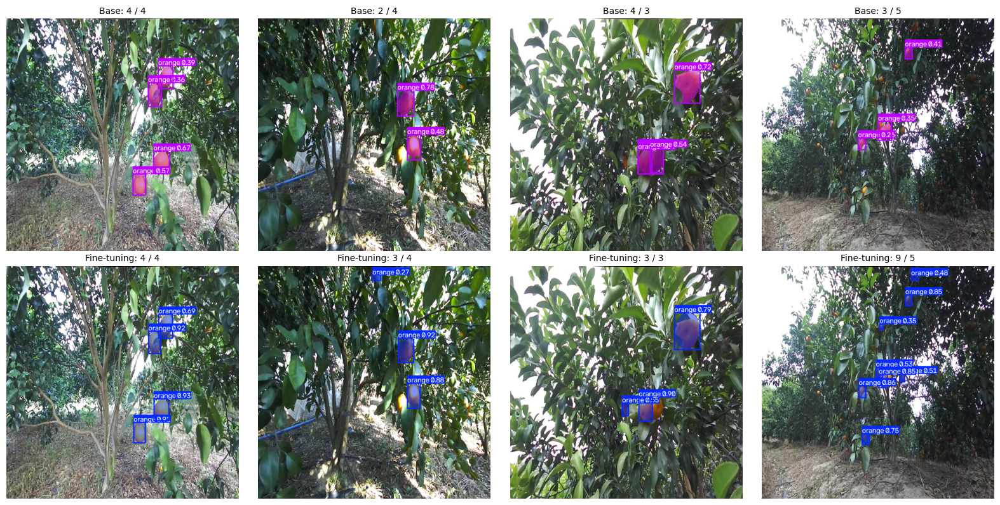

In [ ]:
if ENTRENAR:
    modelo_ft = YOLO(MEJOR_FT)
    _, dib_base = conteo_por_imagen(modelo_base, clases=[COCO_ORANGE], ejemplos=4)
    _, dib_ft = conteo_por_imagen(modelo_ft, imgsz=IMGSZ_FT, ejemplos=4)
    grilla([img for img, _ in dib_base] + [img for img, _ in dib_ft],
           [f"Base: {f['predichas']} / {f['reales']}" for _, f in dib_base]
           + [f"Fine-tuning: {f['predichas']} / {f['reales']}" for _, f in dib_ft])

In [ ]:
if ENTRENAR:
    # Dos tamaños: 640 para la web (más rápido) y 1024 por si hacen falta bordes más precisos.
    modelo_pt = YOLO(MEJOR_FT)
    for imgsz in (IMGSZ, IMGSZ_FT):
        onnx_ft = Path(modelo_pt.export(format='onnx', imgsz=imgsz, nms=True, conf=CONF, device='cpu'))

        # Predicción de control, como en la sección 6: el .onnx tiene que contar lo mismo que el .pt.
        modelo_onnx_ft = YOLO(str(onnx_ft), task='segment')
        for imagen in imagenes_test[:3]:
            n_pt = len(modelo_pt.predict(imagen, conf=CONF, imgsz=imgsz, rect=False, verbose=False)[0].boxes)
            n_onnx = len(modelo_onnx_ft.predict(imagen, conf=CONF, imgsz=imgsz, verbose=False)[0].boxes)
            print(f"{imgsz} px  {imagen.name[:30]:30}  .pt: {n_pt:3}  .onnx: {n_onnx:3}  {'✅' if n_pt == n_onnx else '⚠️'}")

        guardar_para_web(onnx_ft, DRIVE_DIR / f'web_finetune_{imgsz}', f'YOLO26n-seg ajustado a naranjas ({imgsz} px)',
                         0, imgsz, {0: 'orange'})
    print('Para usarlo en la web, copiá el contenido de MyDrive/naranjas/web_finetune_640/ a ThreeDetection/model/.')

Ultralytics 8.4.191 🚀 Python-3.13.16 torch-2.11.0+cu130 CPU (Intel Xeon CPU @ 2.00GHz)
YOLO26n-seg summary (fused): 137 layers, 2,703,783 parameters, 0 gradients, 9.1 GFLOPs

PyTorch: starting from '/content/drive/MyDrive/naranjas/runs/finetune/weights/best.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) ((1, 300, 38), (1, 32, 160, 160)) (6.4 MB)

ONNX: starting export with onnx 1.23.2 opset 18...
ONNX: slimming with onnxslim 0.1.98...
ONNX: export success ✅ 2.3s, saved as '/content/drive/MyDrive/naranjas/runs/finetune/weights/best.onnx' (10.7 MB)

Export complete (2.7s)
Results saved to /content/drive/MyDrive/naranjas/runs/finetune/weights/best.onnx
Predict:         yolo predict task=segment model=/content/drive/MyDrive/naranjas/runs/finetune/weights/best.onnx imgsz=640 
Validate:        yolo val task=segment model=/content/drive/MyDrive/naranjas/runs/finetune/weights/best.onnx imgsz=640 data=/content/orange-solo/data_local.yaml 
Visualize:       https://netron.app
Load

## Próximos pasos

- Copiar `MyDrive/naranjas/web_finetune_640/` a `ThreeDetection/model/` y probar la demo
  (`web/` tiene el modelo base, por si se quiere comparar).
- Comparar el conteo de la web con `conteo_base.csv` usando las mismas imágenes de test.
- Si para la distancia hacen falta bordes más precisos, probar `web_finetune_1024/` y medir los FPS en el navegador.